## Installing all required modules for this lab:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import open3d as o3d
import random

## Next, let's import the data. First, lynx model: (code copied from lab file description)

In [2]:

lynx = np.array([
[209.70, 368.42], [157.63, 332.16], [118.82, 284.21], [80.95, 224.56], [43.08, 244.44], [20.36, 266.67], [-4.26, 293.57], [2.37, 263.16], [-20.36, 292.40], [-39.29, 299.42], [-21.30, 259.65],
[-50.65, 267.84], [-39.29, 242.11], [-55.38, 240.94], [-100.83, 300.58], [-149.11, 345.03], [-172.78, 361.40], [-189.82, 300.58], [-192.66, 225.73], [-181.30, 145.03], [-168.05, 104.09], [-184.14, 66.67],
[-186.98, 31.58], [-183.20, 3.51], [-208.76, -4.68], [-197.40, -29.24], [-182.25, -44.44], [-203.08, -43.27], [-172.78, -92.40], [-131.12, -126.32], [-101.78, -147.37], [-74.32, -163.74], [-110.30, -224.56],
[-143.43, -287.72], [-161.42, -240.94], [-282.60, -221.05], [-388.64, -205.85], [-370.65, -301.75], [-339.41, -397.66], [18.46, -397.66], [345.09, -400.00], [359.29, -378.95], [367.81, -342.69], [346.98, -
362.57], [363.08, -302.92], [357.40, -243.27], [348.88, -266.67], [336.57, -201.17], [290.18, -135.67], [240.00, -118.13], [258.93, -164.91], [257.99, -228.07], [252.31, -271.35], [256.09, -333.33],
[247.57, -359.06], [230.53, -307.60], [194.56, -238.60], [160.47, -181.29], [120.71, -149.71], [165.21, -132.16], [201.18, -100.58], [183.20, -99.42], [221.07, -73.68], [253.25, -24.56], [222.01, -23.39],
[251.36, -1.17], [262.72, 24.56], [234.32, 25.73], [214.44, 42.11], [202.13, 60.82], [220.12, 101.75], [234.32, 160.23], [240.00, 230.41], [232.43, 316.96]
]).T

## Airplane model: (code copied from lab file description)

In [ ]:
def read_off(filename: str):
    with open(filename, 'r') as f:
        # Перевіряємо, чи перший рядок починається з OFF
        if 'OFF' != f.readline().strip():
            raise ValueError('Not a valid OFF header')
        
        # Зчитуємо кількість вершин, граней та ребер (третє значення часто ігнорується)
        n_verts, n_faces, _ = map(int, f.readline().strip().split())
        
        # Зчитуємо координати всіх вершин (x, y, z)
        verts = [list(map(float, f.readline().strip().split())) for _ in range(n_verts)]
        
        # Зчитуємо грані: перше число у рядку - кількість вершин грані (ігноруємо), далі індекси
        faces = [list(map(int, f.readline().strip().split()[1:])) for _ in range(n_faces)]
        
        # Повертаємо вершини у вигляді масиву NumPy та список граней
        return np.array(verts), faces

vertices, faces = read_off("airplane_0627.off")


FileNotFoundError: [Errno 2] No such file or directory: 'airplane/test/airplane_0627.off'

## First task:

In [ ]:
def stretch(x: np.array, a: float, b: float):
    x_copy = x.copy()
    m = np.array(
        [
            [a, 0],
            [0, b]
        ])
    x_stretch = m @ x_copy
    return x_stretch, m

def shear(x: np.array, a: float, b: float):
    x_copy = x.copy()
    m = np.array(
        [
            [1, a],
            [b, 1]
        ])
    x_shear = m @ x_copy
    return x_shear, m

def reflection(x: np.array, a: float, b: float):
    x_copy = x.copy()
    m = (1.0 / (a**2 + b**2)) * np.array(
        [
            [a**2 - b**2, 2*a*b],
            [2*a*b, b**2 - a**2]
        ])
    x_reflection = m @ x_copy
    return x_reflection, m

def rotation(x: np.array, angle: float):
    x_copy = x.copy()
    m = np.array(
        [
            [np.cos(angle), -np.sin(angle)],
            [np.sin(angle), np.cos(angle)]
        ])
    x_rotation = m @ x_copy
    return x_rotation, m

## Function to visualize and compare 2d transformations:

In [ ]:
def plot_2d(original, transformed, matrix, title) -> None:
    fig, ax = plt.subplots(figsize=(6, 6))

    ax.plot(original[0, :], original[1, :], color="red", label="Original")

    ax.plot(transformed[0, :], transformed[1, :], color="blue", label="Transformed")

    ax.set_aspect("equal", adjustable='datalim')
    ax.set_title(title)
    ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()
    print(matrix)

## Visualization of task 1 functions:

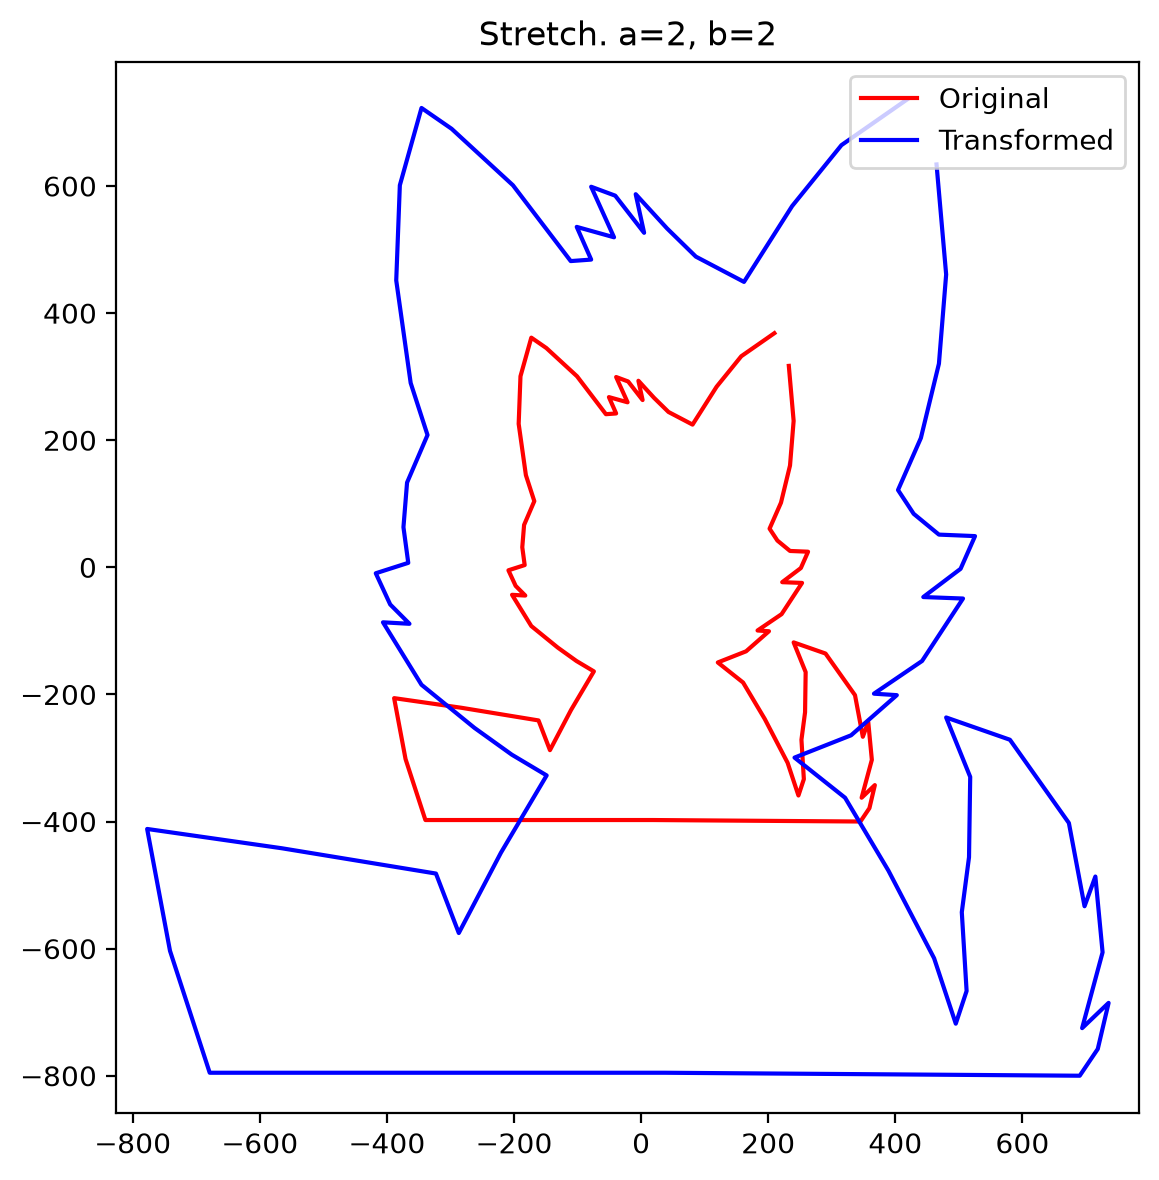

[[2 0]
 [0 2]]


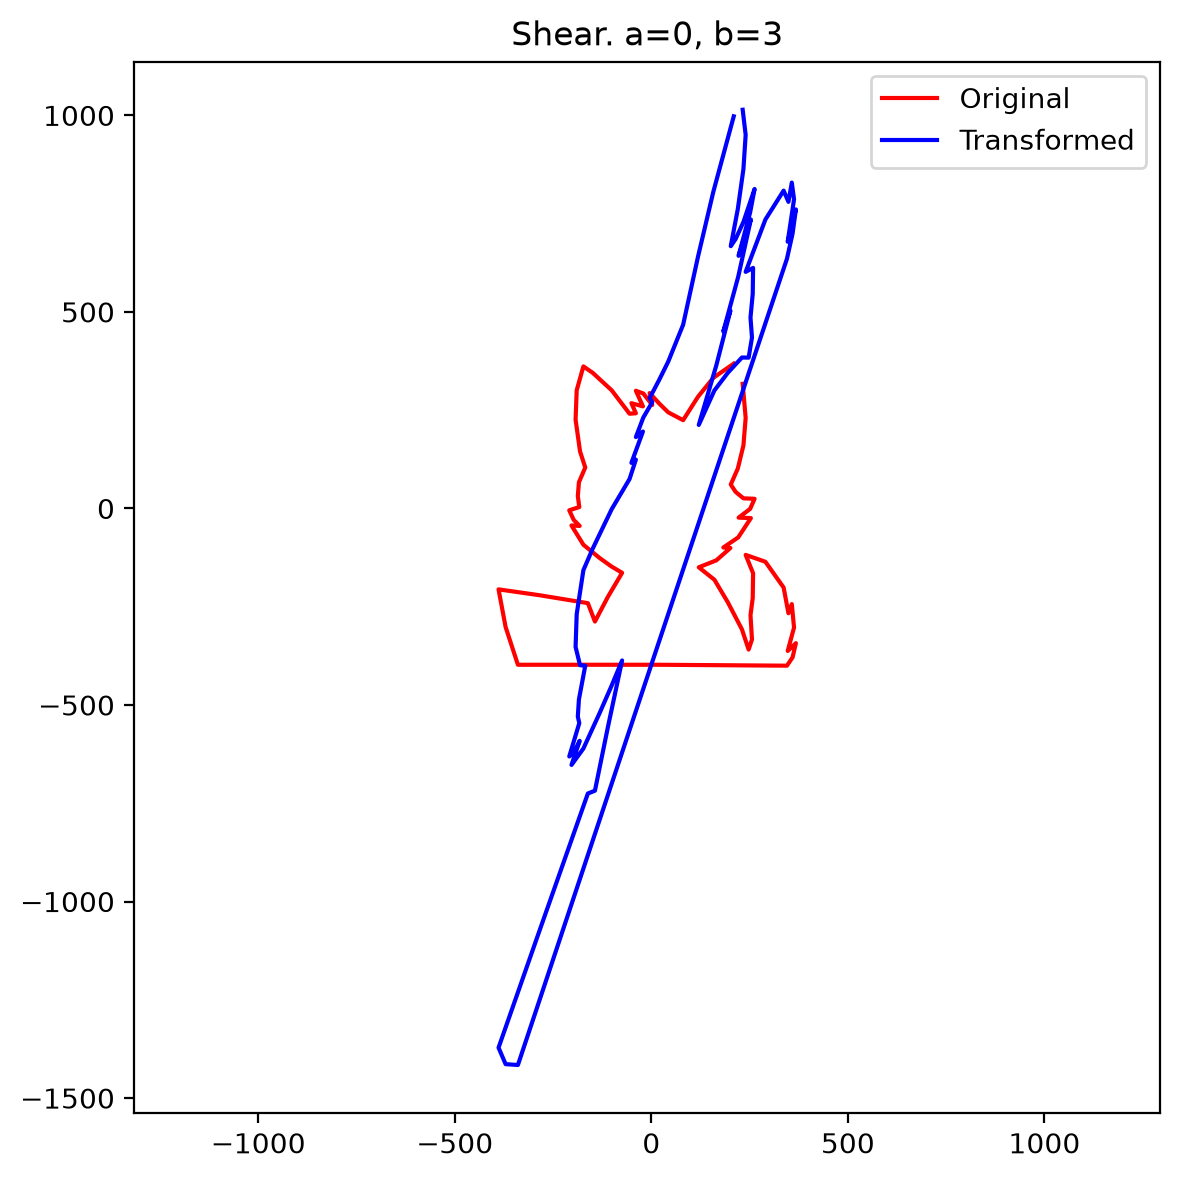

[[1 0]
 [3 1]]


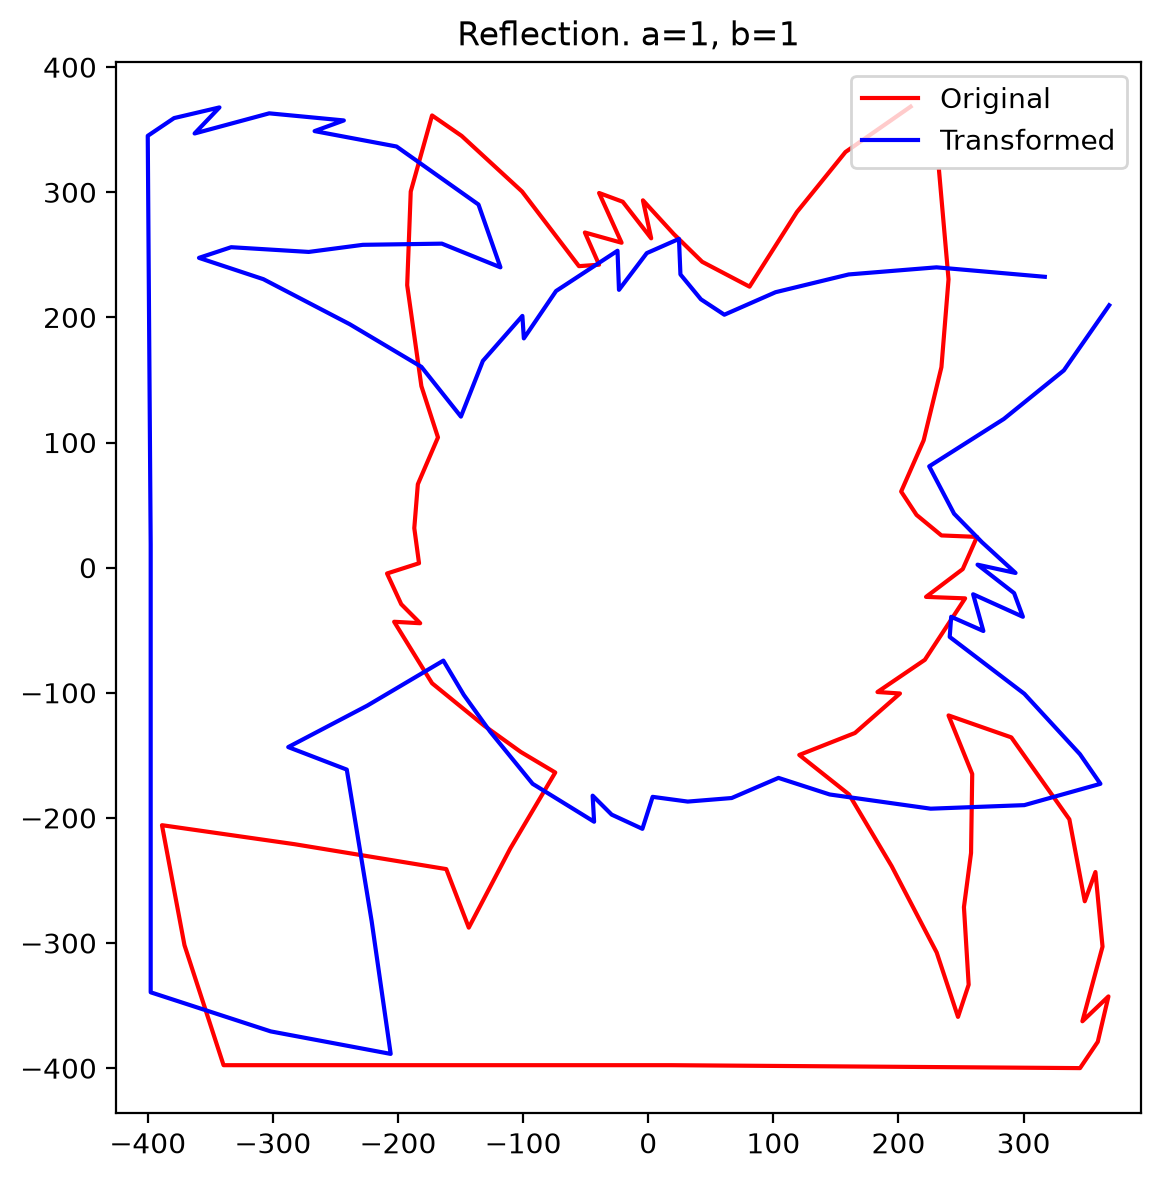

[[0. 1.]
 [1. 0.]]


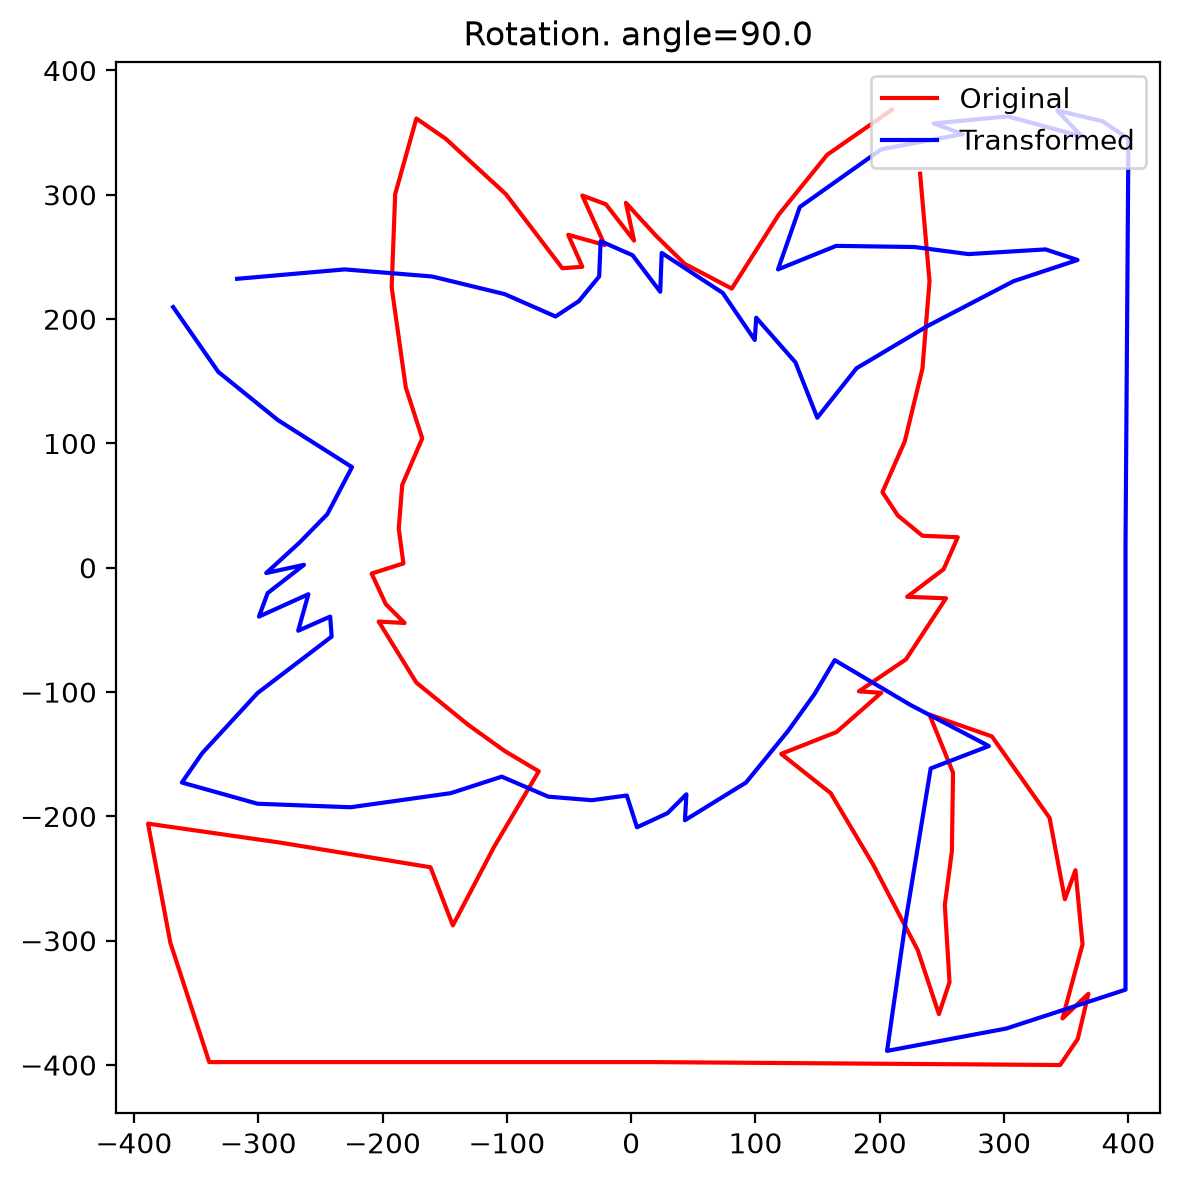

[[ 6.123234e-17 -1.000000e+00]
 [ 1.000000e+00  6.123234e-17]]


In [ ]:
def visualizations_2d():
    a, b = 2, 2
    streched, m_stretch = stretch(lynx, a, b)
    plot_2d(lynx, streched, m_stretch, f"Stretch. a={a}, b={b}")

    a, b = 0, 3
    sheared, m_shear = shear(lynx, a, b)
    plot_2d(lynx, sheared, m_shear, f"Shear. a={a}, b={b}")

    a, b = 1, 1
    reflected, m_reflect = reflection(lynx, a, b)
    plot_2d(lynx, reflected, m_reflect, f"Reflection. a={a}, b={b}")

    angle = np.pi/2
    rotated, m_rotate = rotation(lynx, angle)
    plot_2d(lynx, rotated, m_rotate, f"Rotation. angle={angle/np.pi*180}")
    
visualizations_2d()

## Visualization of task 2:

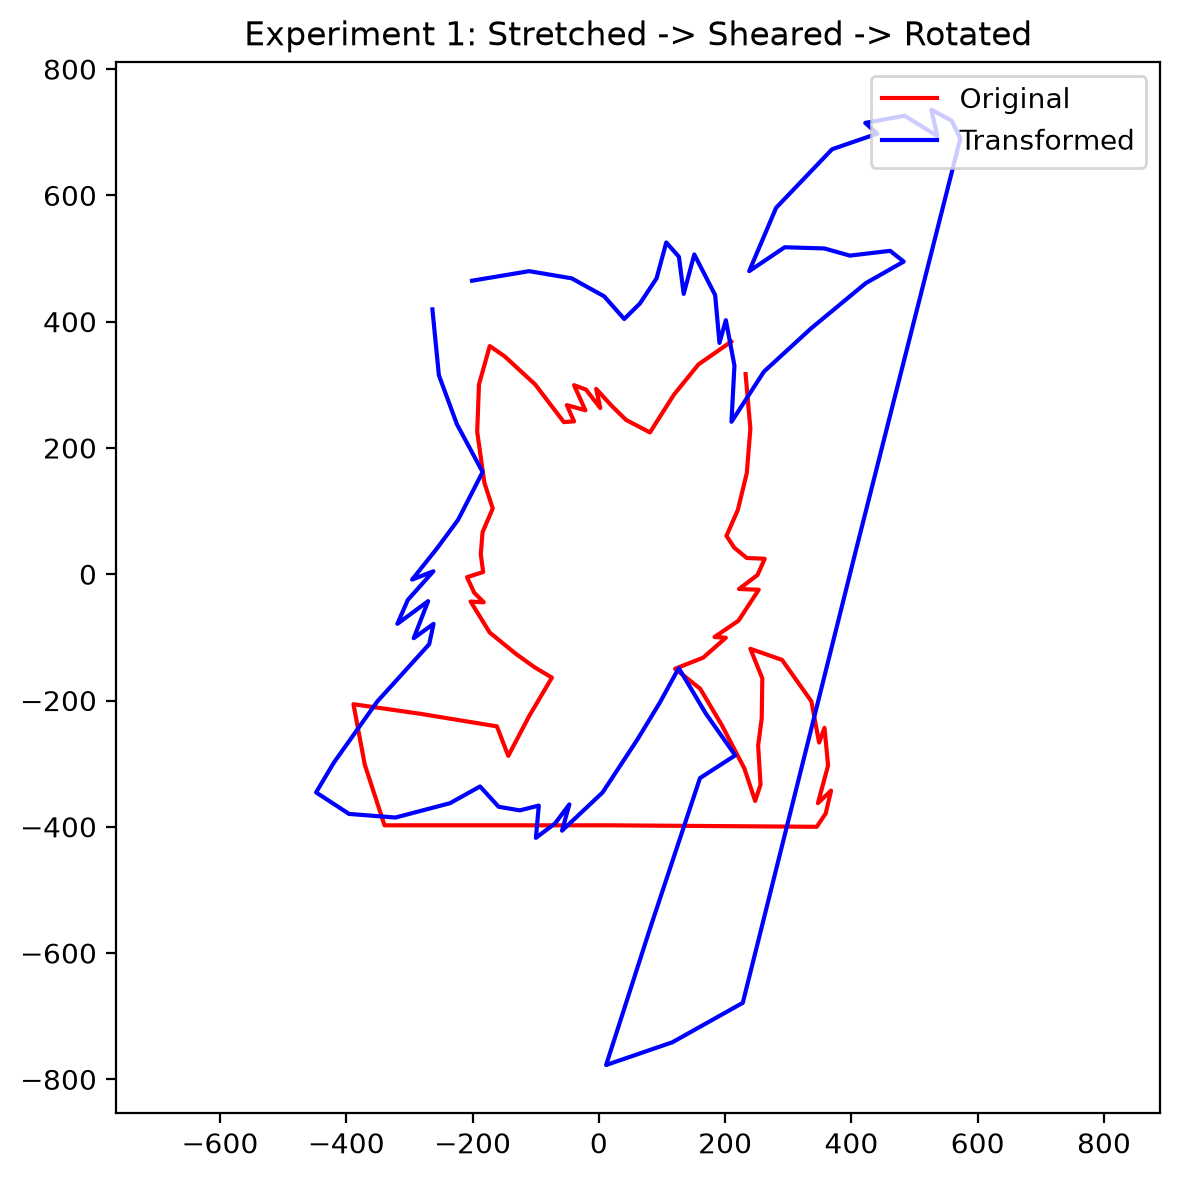

[[ 5.0000000e-01 -1.0000000e+00]
 [ 2.0000000e+00  1.2246468e-16]]


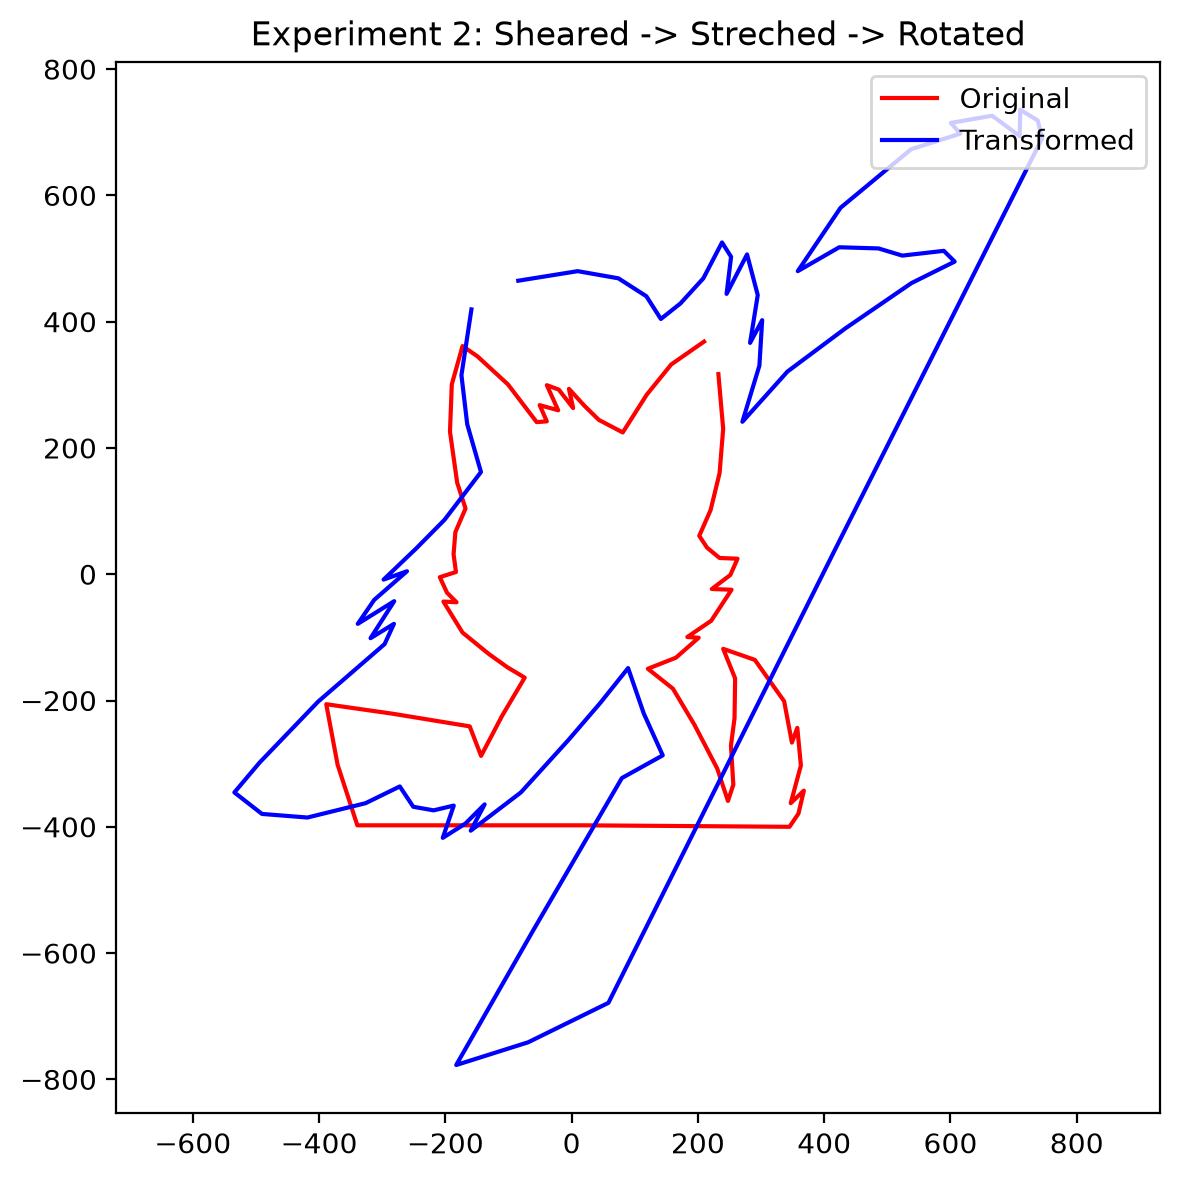

[[ 1.0000000e+00 -1.0000000e+00]
 [ 2.0000000e+00  1.2246468e-16]]


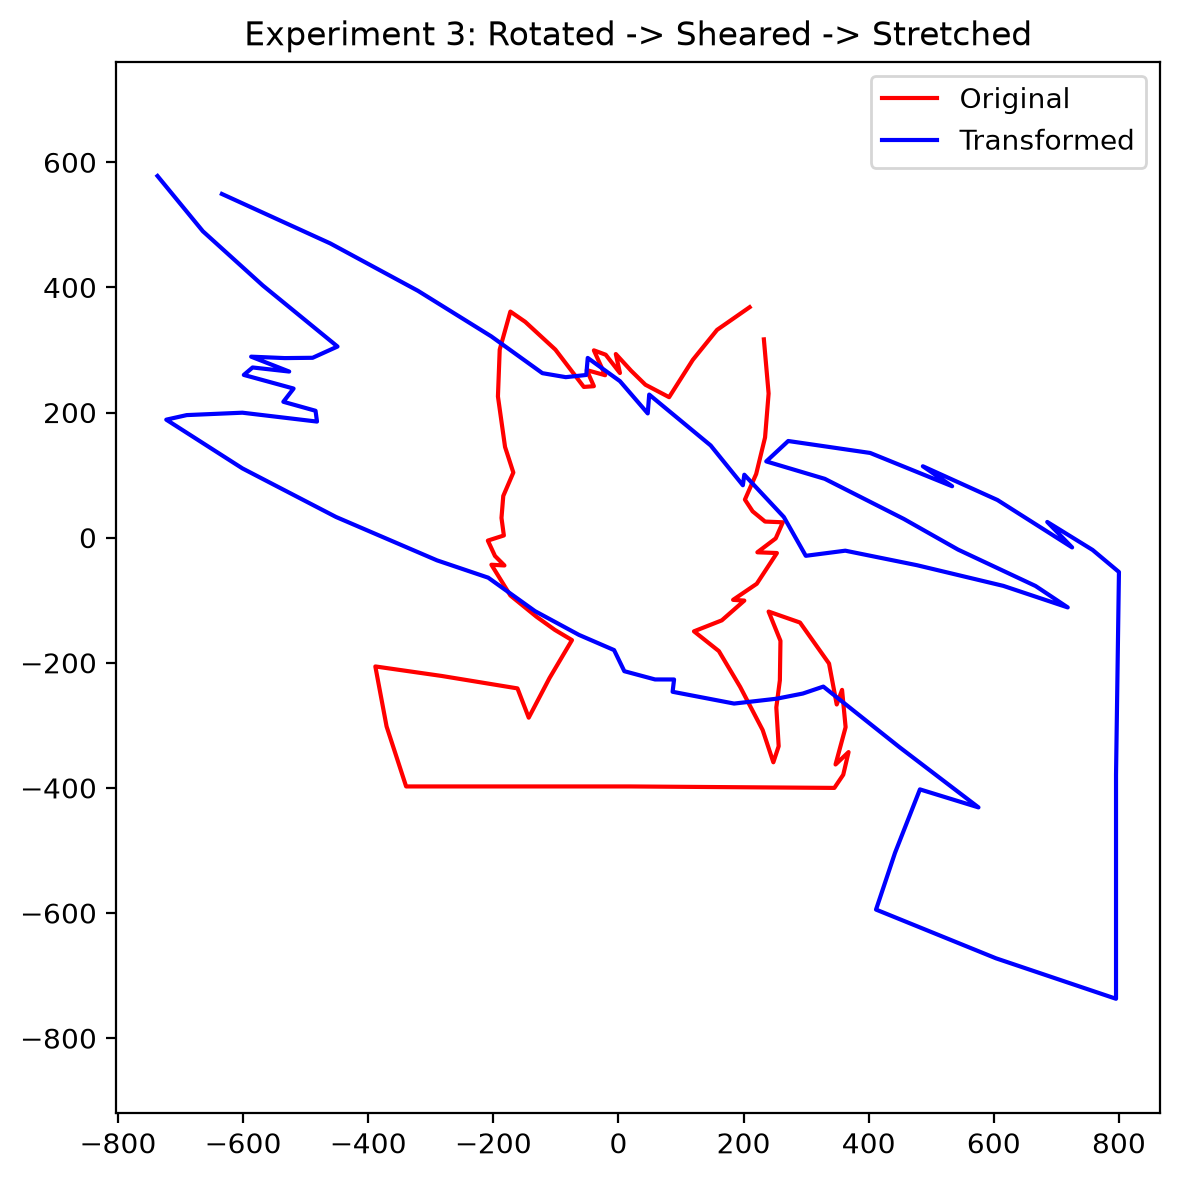

[[ 6.123234e-17 -2.000000e+00]
 [ 1.000000e+00  1.000000e+00]]


In [ ]:

def experiments() -> None:

    _, m_stretch = stretch(lynx, 1, 2)
    _, m_shear = shear(lynx, 1/2, 0)
    _, m_rotate = rotation(lynx, np.pi / 2)
    
    # experiment 1
    m_exp_1 = m_stretch @ m_shear @ m_rotate
    lynx_1 = m_exp_1 @ lynx.copy()
    plot_2d(lynx, lynx_1, m_exp_1, "Experiment 1: Rotated -> Sheared -> Streched")

    # experiment 2
    m_exp_2 = m_shear @ m_stretch @ m_rotate
    lynx_2 = m_exp_2 @ lynx.copy()
    plot_2d(lynx, lynx_2, m_exp_2, "Experiment 2: Rotated -> Streched -> Sheared")

    # experiment 3
    m_exp_3 = m_rotate @ m_shear @ m_stretch
    lynx_3 = m_exp_3 @ lynx.copy()
    plot_2d(lynx, lynx_3, m_exp_3, "Experiment 3: Streched -> Sheared -> Rotated")

experiments()

## Conclusions to task 2
### Final result depends on the order of transformation

## Part 2. 3d rotation

## First step, creating the functions for each 3D rotation:

In [ ]:
def rotate_xy(x: np.array, angle: float):
    xy = np.array([
        [np.cos(angle), -np.sin(angle), 0],
        [np.sin(angle), np.cos(angle), 0],
        [0, 0, 1]
    ])
    x_copy = x.copy()
    transformed = x_copy @ xy.T
    return transformed, xy

def rotate_yz(x: np.array, angle: float):
    yz = np.array([
        [1, 0, 0],
        [0, np.cos(angle), -np.sin(angle)],
        [0, np.sin(angle), np.cos(angle)]
    ])
    x_copy = x.copy()
    transformed = x_copy @ yz.T
    return transformed, yz

def rotate_xz(x: np.array, angle: float):
    xz = np.array([
        [np.cos(angle), 0, -np.sin(angle)],
        [0, 1, 0],
        [np.sin(angle), 0, np.cos(angle)]
    ])
    x_copy = x.copy()
    transformed = x_copy @ xz.T

    return transformed, xz

## Function for the visualization: (Took from the lab file)

In [ ]:
# Функція для візуалізації OFF-моделі у вигляді сітки та точок
# (зручно бачити, як змінюється модель після трансформацій)
def plot_off(vertices, faces, title: str) -> None:
    fig = plt.figure(figsize=(8, 8))                  # створюємо вікно
    ax = fig.add_subplot(111, projection='3d')        # додаємо 3D координатну систему

    # Створюємо полігональну сітку з граней (faces) та додаємо її на графік
    mesh = Poly3DCollection([vertices[face] for face in faces],
                           alpha=0.3, edgecolor='k')  # прозорість 0.3, чорні ребра
    ax.add_collection3d(mesh)

    # Додаємо вершини як червоні точки
    ax.scatter(vertices[:, 0], vertices[:, 1], vertices[:, 2], s=2, c='gray')

    # Підписуємо осі
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")

    # Автоматично масштабуємо сцену під модель
    ax.auto_scale_xyz(vertices[:, 0], vertices[:, 1], vertices[:, 2])
    ax.set_title(title)
    plt.show()  # показуємо результат

## Task 3 Functions visualizations

Matrix XY. 90.0 degrees:
 [[ 6.123234e-17 -1.000000e+00  0.000000e+00]
 [ 1.000000e+00  6.123234e-17  0.000000e+00]
 [ 0.000000e+00  0.000000e+00  1.000000e+00]]


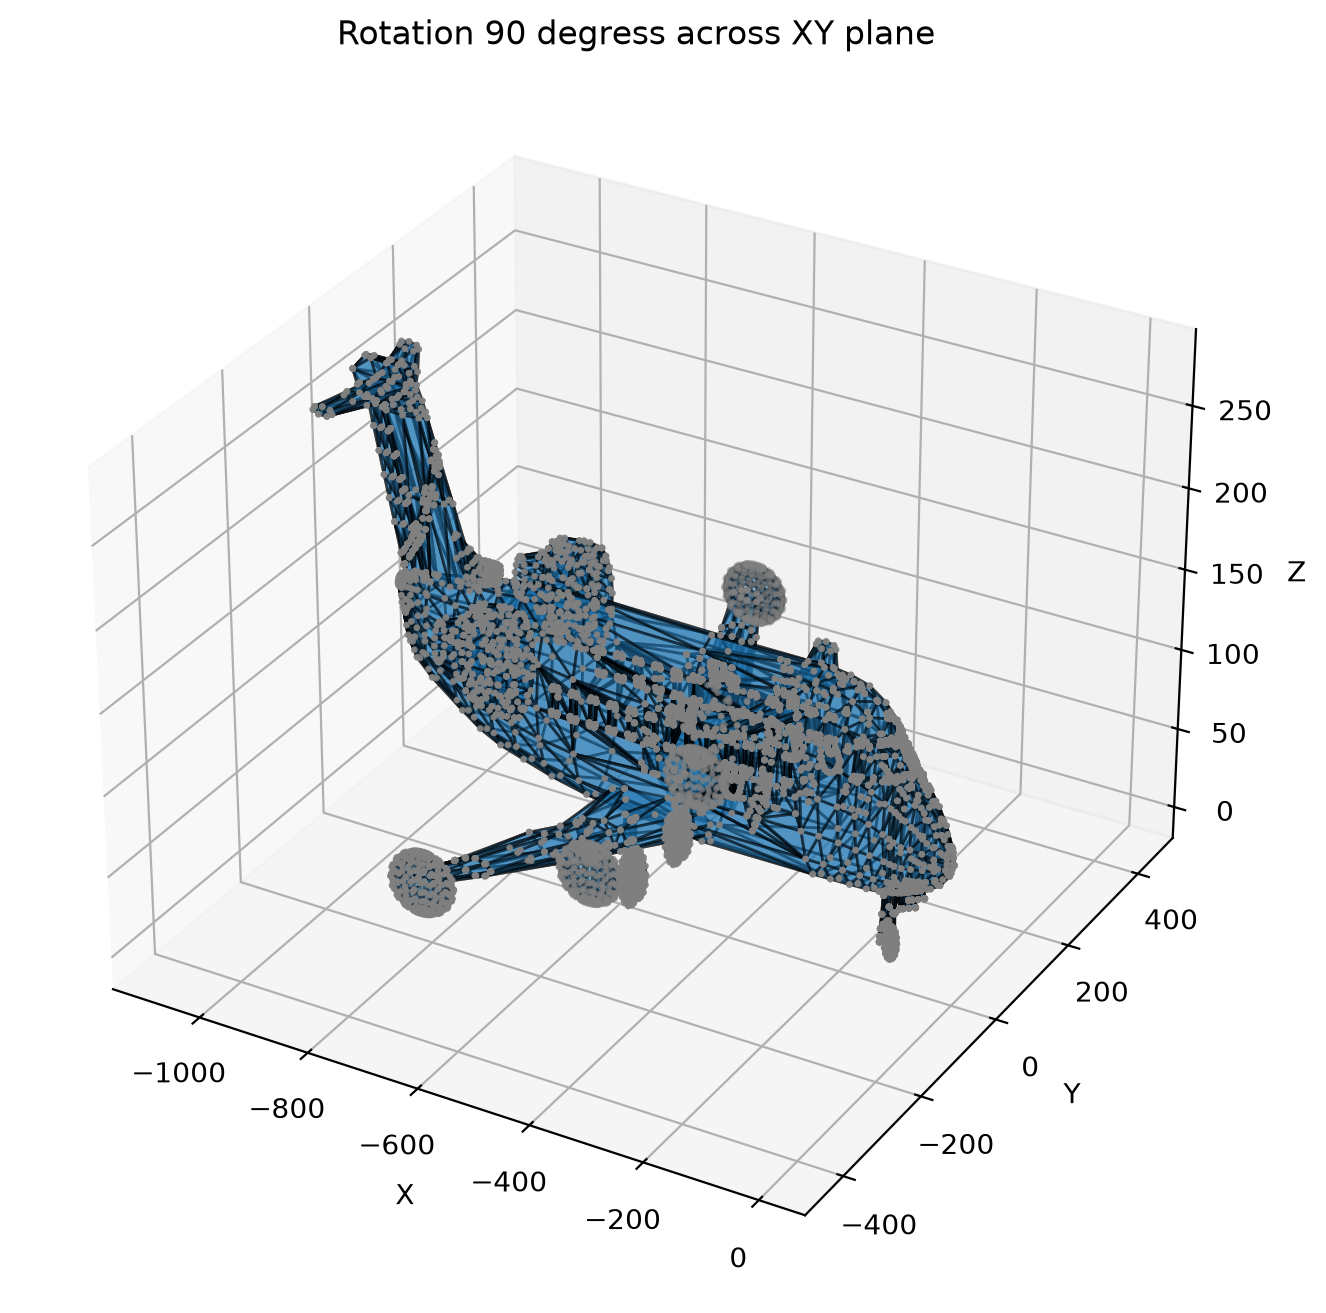

Matrix XY. 45.0 degrees:
 [[ 6.123234e-17 -1.000000e+00  0.000000e+00]
 [ 1.000000e+00  6.123234e-17  0.000000e+00]
 [ 0.000000e+00  0.000000e+00  1.000000e+00]]


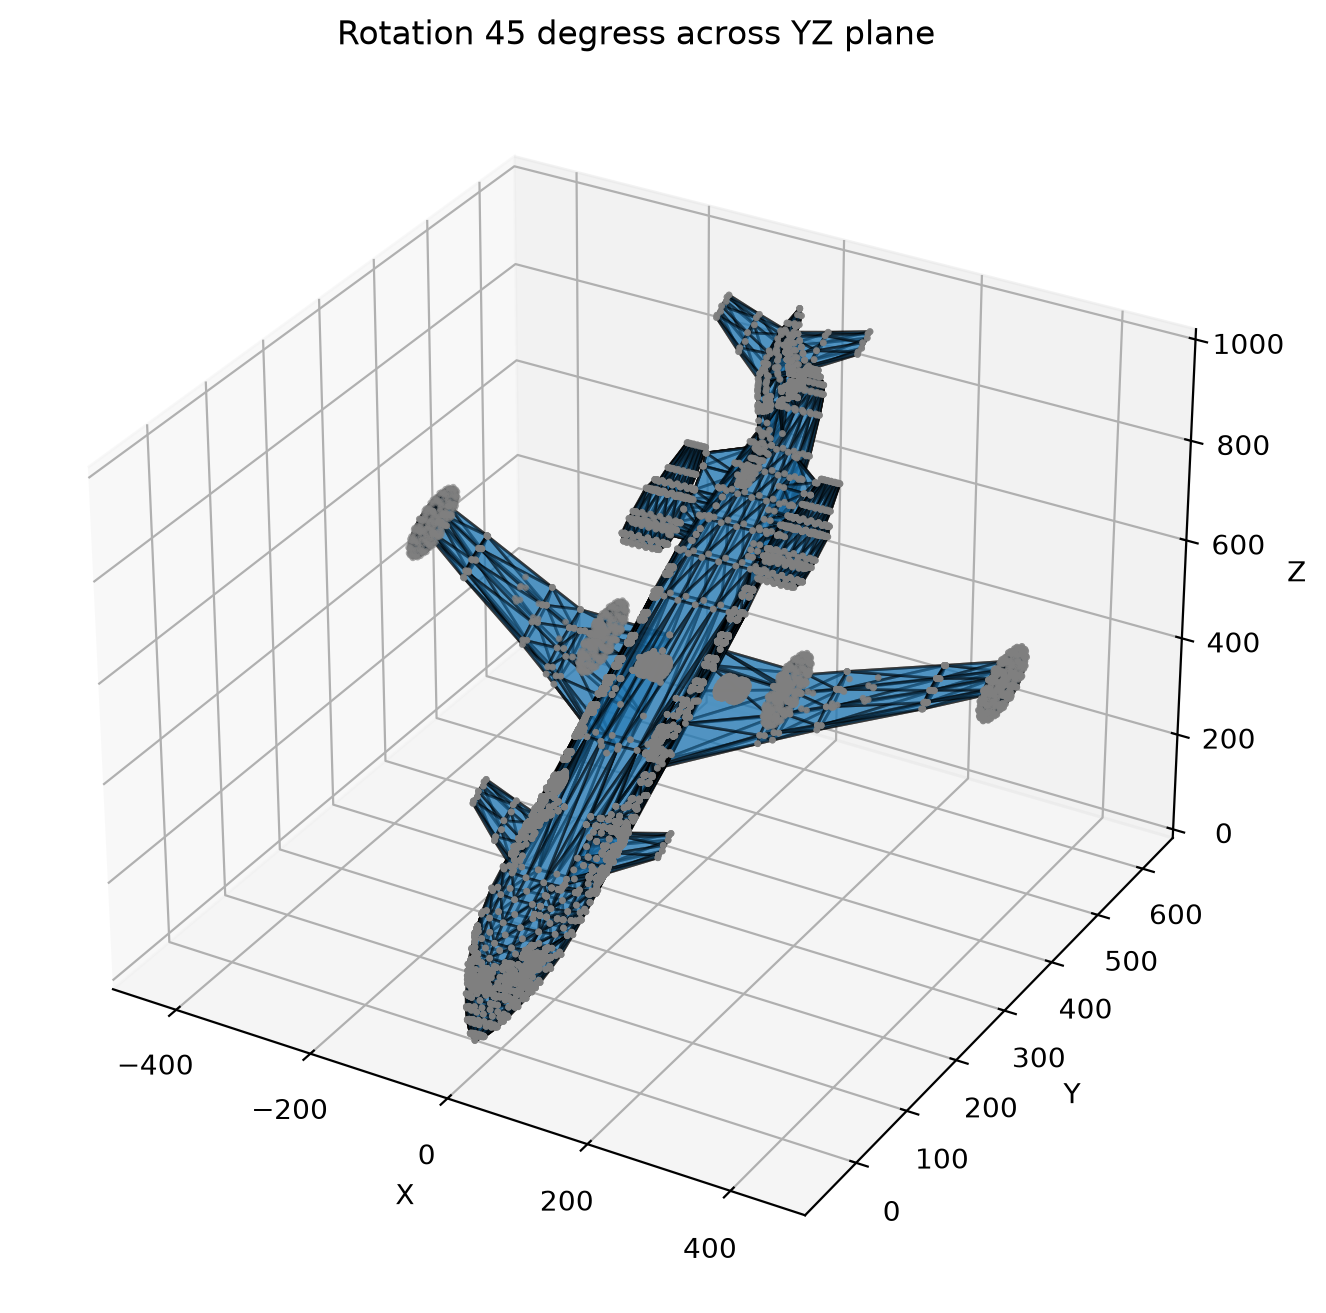

Matrix XY. 180.0 degrees:
 [[ 6.123234e-17 -1.000000e+00  0.000000e+00]
 [ 1.000000e+00  6.123234e-17  0.000000e+00]
 [ 0.000000e+00  0.000000e+00  1.000000e+00]]


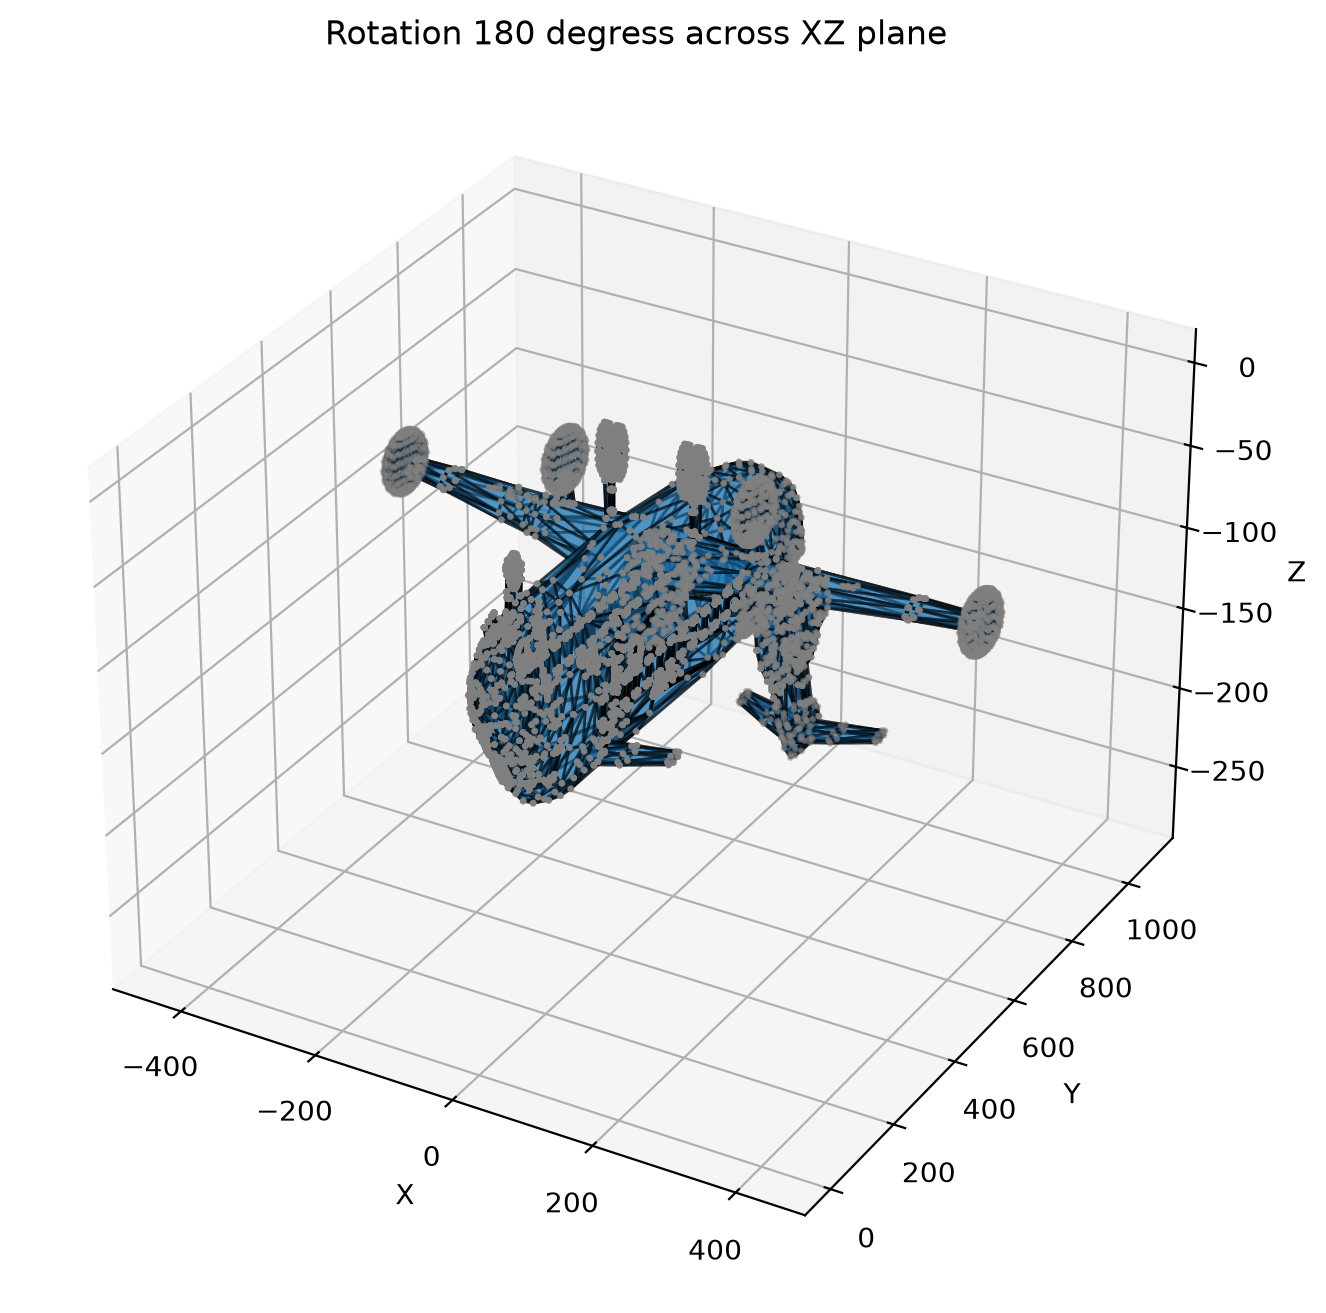

In [ ]:
def visualizations_3d():
    angle = np.pi / 2
    vertices_xy, m_xy = rotate_xy(vertices, angle)
    print(f"Matrix XY. {angle/np.pi*180} degrees:\n", m_xy)
    plot_off(vertices_xy, faces, "Rotation 90 degress across XY plane")

    angle = np.pi / 4
    vertices_yz, m_yz = rotate_yz(vertices, angle)
    print(f"Matrix XY. {angle/np.pi*180} degrees:\n", m_xy)
    plot_off(vertices_yz, faces, "Rotation 45 degress across YZ plane")

    angle = np.pi
    vertices_xz, m_xz = rotate_xz(vertices, angle)
    print(f"Matrix XY. {angle/np.pi*180} degrees:\n", m_xy)
    plot_off(vertices_xz, faces, "Rotation 180 degress across XZ plane")

visualizations_3d()

## Task 4. Now let's see the transformations of this plane step-by step:

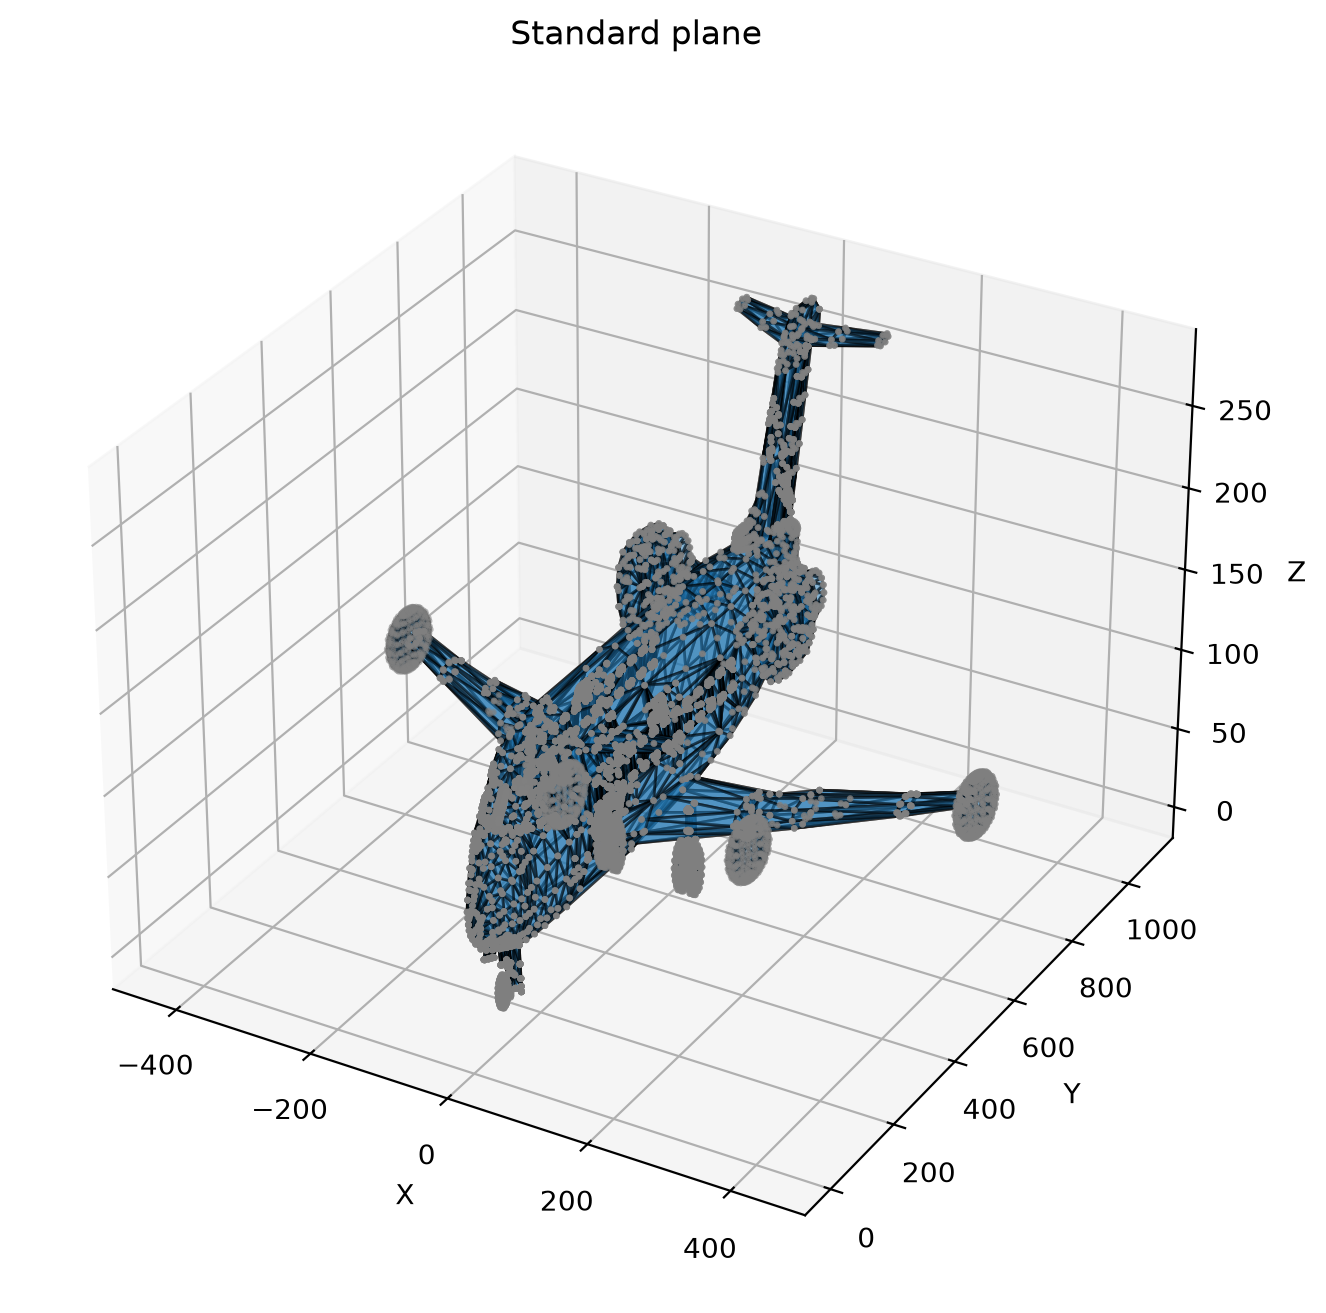

Transformation Matrix:
 [[ 1.2246468e-16  1.8369702e-16 -1.0000000e+00]
 [-1.0000000e+00 -6.1232340e-17 -1.2246468e-16]
 [-6.1232340e-17  1.0000000e+00  1.8369702e-16]]


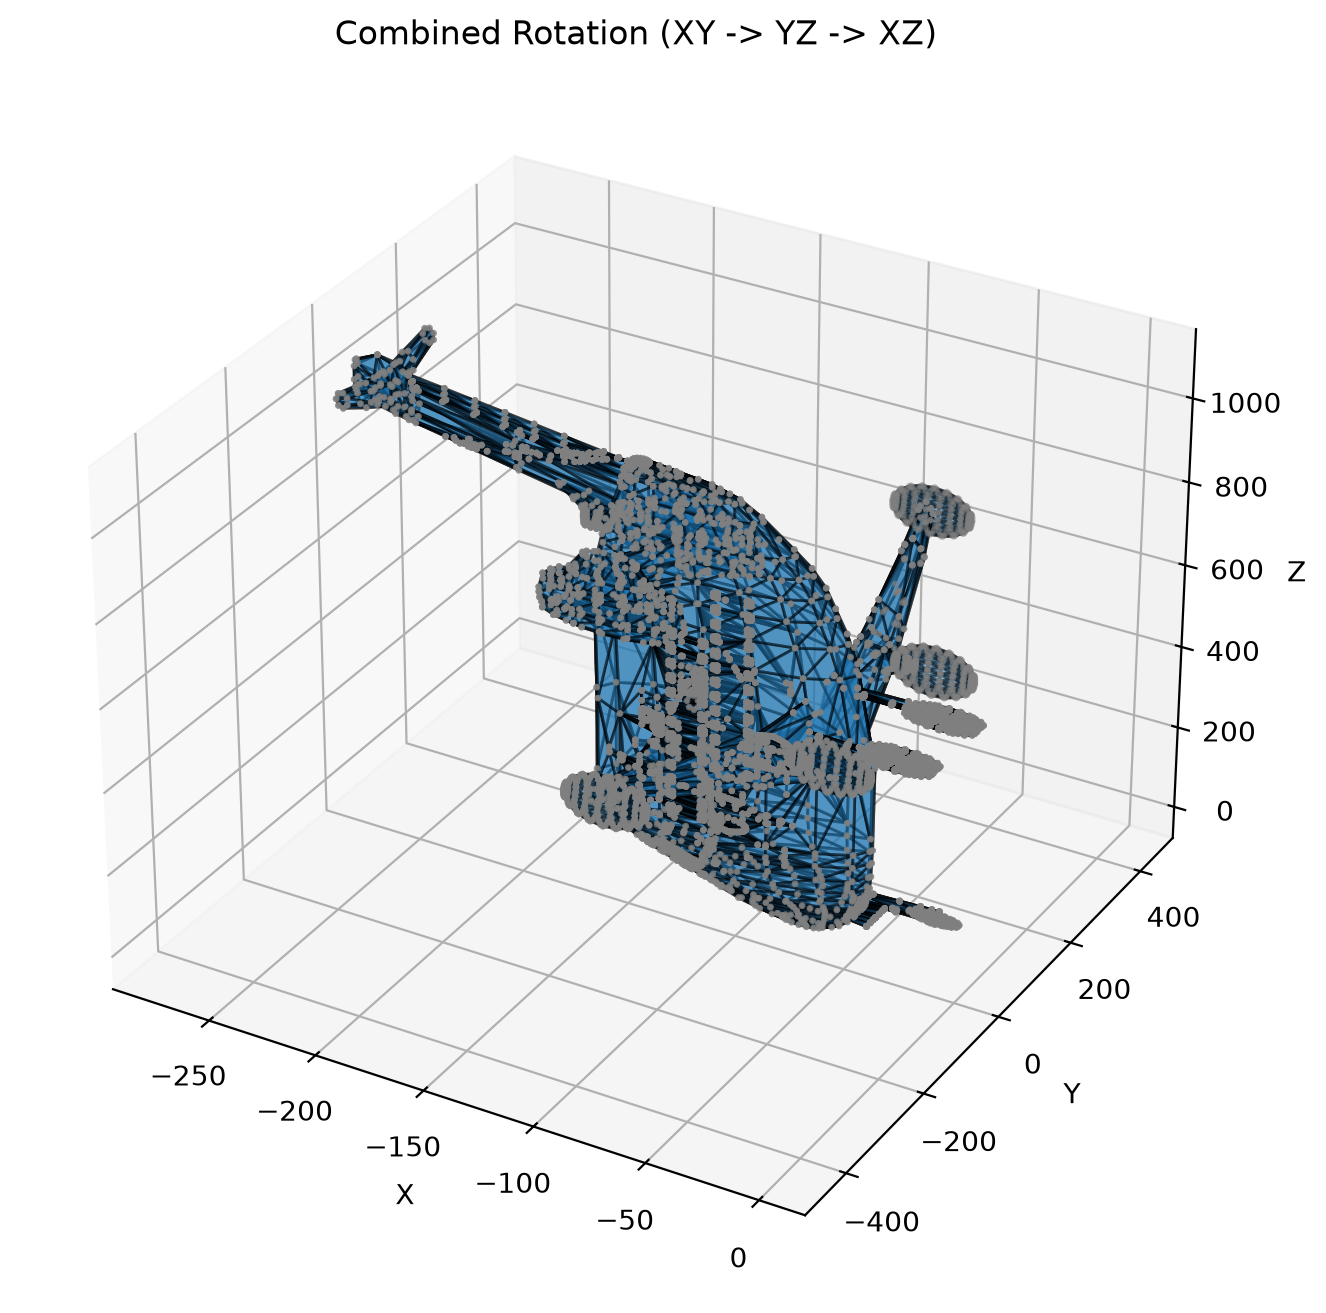

In [ ]:
# Before transformations
plot_off(vertices, faces, "Standard plane")

degrees_90 = np.pi/2
degrees_180 = np.pi
degrees_270 = np.pi * 3/2

_, m_xy = rotate_xy(vertices, degrees_90)
_, m_yz = rotate_yz(vertices, degrees_180)
_, m_xz = rotate_xz(vertices, degrees_270)

m_final = m_xz @ m_yz @ m_xy
vertices_final = vertices @ m_final.T

print("Transformation Matrix:\n", m_final)
plot_off(vertices_final, faces, "Combined Rotation (XY -> YZ -> XZ)")
